# Phase 3: ML Model Development, Comparison & Evaluation
## Project: AI-Assisted Code "Silent Regression" Forecaster

### Empirical Scope & Problem Formulation
- **Operational Task:** Just-In-Time (JIT) Code-Change Defect-Risk Predictor on the ApacheJIT corpus.
- **Prediction Target:** `buggy` (Defect-inducing changes identified via SZZ heuristic; does not directly measure test evasion).
- **Split Architecture:**
  - Internal Fitting Set: Historical commits (2003–2014, $n = 30,218$).
  - Internal Validation Set: Historical holdout (2015–2016, $n = 14,616$).
  - Untouched External Test Set: Future deployment epoch (2017–2019, $n = 30,111$).
- **No Lookahead Bias:** Model selection, tuning, and threshold selection are completed on validation data before touching the test set.


In [1]:
import os
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve
)

from src.train_models import (
    create_candidate_models,
    evaluate_predictions,
    get_paths,
    load_training_data,
    run_model_comparison,
)
from src.evaluate_models import load_test_data, evaluate_on_test_set

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

paths = get_paths()
print("Environment and module paths configured successfully.")


Environment and module paths configured successfully.


In [2]:
X_train, y_train, years = load_training_data(paths)
print(f"Full Training Corpus: {X_train.shape[0]:,} rows × {X_train.shape[1]} features (Years {years.min()}–{years.max()})")

# Chronological partition (Fit: <= 2014, Val: 2015-2016)
fit_mask = years <= 2014
val_mask = years > 2014

X_fit, y_fit = X_train[fit_mask], y_train[fit_mask]
X_val, y_val = X_train[val_mask], y_train[val_mask]

print(f"Internal Fit Set:       {X_fit.shape[0]:,} rows (Years {years[fit_mask].min()}–{years[fit_mask].max()}, Defect Rate: {y_fit.mean()*100:.2f}%)")
print(f"Internal Validation Set: {X_val.shape[0]:,} rows (Years {years[val_mask].min()}–{years[val_mask].max()}, Defect Rate: {y_val.mean()*100:.2f}%)")


Full Training Corpus: 44,834 rows × 26 features (Years 2003–2016)
Internal Fit Set:       30,218 rows (Years 2003–2014, Defect Rate: 50.19%)
Internal Validation Set: 14,616 rows (Years 2015–2016, Defect Rate: 49.64%)


In [3]:
print("Training and evaluating candidate models on internal validation set...")
comparison = run_model_comparison(X_train, y_train, years, split_year=2014, random_state=42)

comp_df = pd.DataFrame(comparison['comparison_results']).T.sort_values('pr_auc', ascending=False)
display(comp_df)


Training and evaluating candidate models on internal validation set...
Fitting Logistic Regression on 30,218 training records (<= 2014)...


  * Logistic Regression: PR-AUC = 0.8024, ROC-AUC = 0.8114, F1 = 0.7265
Fitting Decision Tree on 30,218 training records (<= 2014)...


  * Decision Tree: PR-AUC = 0.7736, ROC-AUC = 0.7981, F1 = 0.7245
Fitting Random Forest on 30,218 training records (<= 2014)...


  * Random Forest: PR-AUC = 0.8152, ROC-AUC = 0.8227, F1 = 0.7480
Fitting Hist Gradient Boosting on 30,218 training records (<= 2014)...


  * Hist Gradient Boosting: PR-AUC = 0.8066, ROC-AUC = 0.8168, F1 = 0.7397


,pr_auc,roc_auc,f1,precision,recall,balanced_accuracy,brier_score,log_loss
Random Forest,0.8152,0.8227,0.7480,0.7315,0.7653,0.7442,0.1725,0.5184
Hist Gradient Boosting,0.8066,0.8168,0.7397,0.7346,0.7449,0.7398,0.1748,0.5243
Logistic Regression,0.8024,0.8114,0.7265,0.7585,0.6970,0.7392,0.1779,0.5392
Decision Tree,0.7736,0.7981,0.7245,0.7193,0.7297,0.7245,0.1844,0.5506


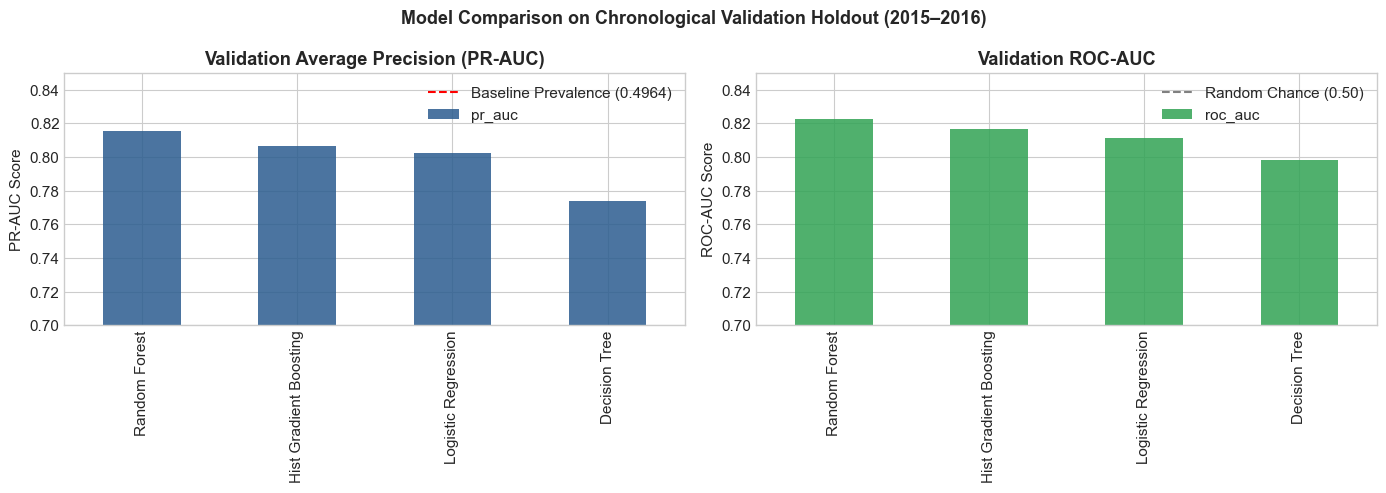

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PR-AUC Bar chart
comp_df['pr_auc'].plot(kind='bar', ax=axes[0], color='#2b5c8f', alpha=0.85)
axes[0].set_title('Validation Average Precision (PR-AUC)', fontweight='bold')
axes[0].set_ylabel('PR-AUC Score')
axes[0].set_ylim(0.7, 0.85)
axes[0].axhline(y=y_val.mean(), color='red', linestyle='--', label=f'Baseline Prevalence ({y_val.mean():.4f})')
axes[0].legend()

# ROC-AUC Bar chart
comp_df['roc_auc'].plot(kind='bar', ax=axes[1], color='#31a354', alpha=0.85)
axes[1].set_title('Validation ROC-AUC', fontweight='bold')
axes[1].set_ylabel('ROC-AUC Score')
axes[1].set_ylim(0.7, 0.85)
axes[1].axhline(y=0.5, color='gray', linestyle='--', label='Random Chance (0.50)')
axes[1].legend()

plt.suptitle('Model Comparison on Chronological Validation Holdout (2015–2016)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


Operational Threshold Analysis for Random Forest on Validation Set:


,threshold,precision,recall,f1,balanced_accuracy
0,0.30,0.6250,0.9229,0.7453,0.6885
1,0.35,0.6525,0.8906,0.7532,0.7115
2,0.40,0.6793,0.8555,0.7573,0.7287
3,0.45,0.7061,0.8142,0.7563,0.7401
4,0.50,0.7315,0.7653,0.7480,0.7442
5,0.55,0.7560,0.7148,0.7348,0.7437
6,0.60,0.7778,0.6609,0.7146,0.7374
7,0.65,0.8082,0.5982,0.6875,0.7291
8,0.70,0.8338,0.5159,0.6374,0.7073


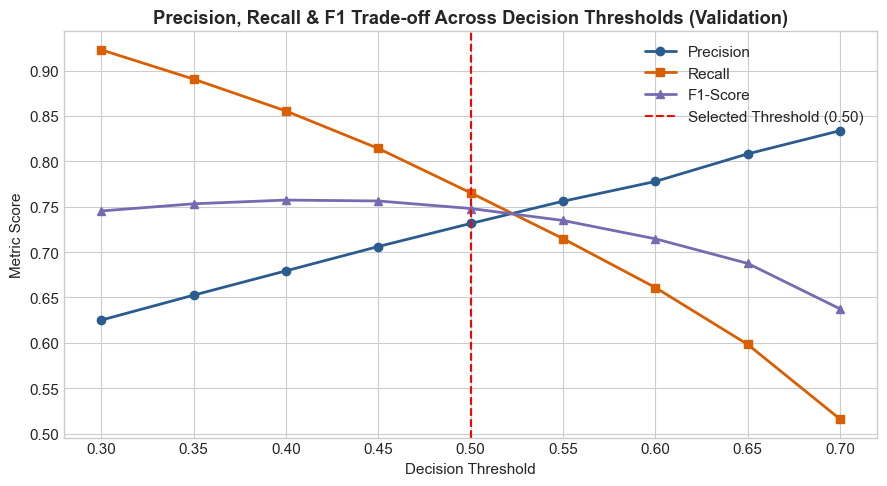

In [5]:
th_df = pd.DataFrame(comparison['threshold_analysis'])
print("Operational Threshold Analysis for Random Forest on Validation Set:")
display(th_df)

plt.figure(figsize=(9, 5))
plt.plot(th_df['threshold'], th_df['precision'], 'o-', label='Precision', color='#2b5c8f', lw=2)
plt.plot(th_df['threshold'], th_df['recall'], 's-', label='Recall', color='#d95f02', lw=2)
plt.plot(th_df['threshold'], th_df['f1'], '^-', label='F1-Score', color='#756bb1', lw=2)
plt.axvline(x=0.50, color='red', linestyle='--', label='Selected Threshold (0.50)')
plt.xlabel('Decision Threshold')
plt.ylabel('Metric Score')
plt.title('Precision, Recall & F1 Trade-off Across Decision Thresholds (Validation)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


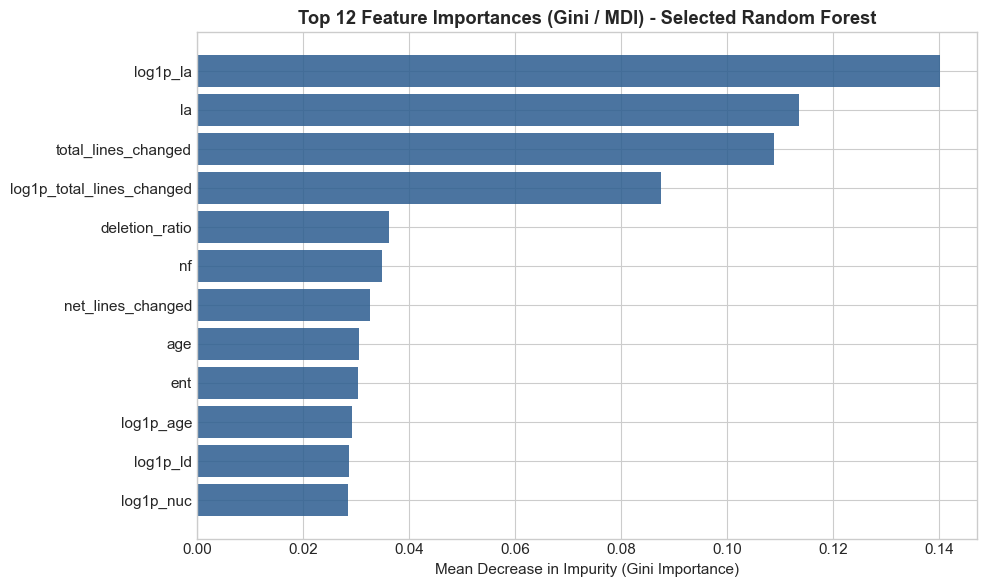

In [6]:
selected_model = joblib.load(paths['models_dir'] / 'selected_model.joblib')
top_n = 12
importances_series = pd.Series(selected_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(top_n)[::-1]

plt.figure(figsize=(10, 6))
plt.barh(importances_series.index, importances_series.values, color='#2b5c8f', alpha=0.85)
plt.title(f'Top {top_n} Feature Importances (Gini / MDI) - Selected Random Forest', fontweight='bold')
plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.tight_layout()
plt.show()


In [7]:
X_test, y_test, test_years = load_test_data(paths)
print(f"Loaded External Test Set: {X_test.shape[0]:,} commits (Years {test_years.min()}–{test_years.max()})")

final_eval = evaluate_on_test_set(selected_model, X_test, y_test, threshold=0.50)

eval_summary = pd.DataFrame([{
    'Metric': 'Average Precision (PR-AUC)', 'Model Score': final_eval['pr_auc'], 'Baseline Reference': final_eval['baseline_pr_auc_prevalence']
}, {
    'Metric': 'ROC-AUC', 'Model Score': final_eval['roc_auc'], 'Baseline Reference': 0.5000
}, {
    'Metric': 'Recall (th=0.50)', 'Model Score': f"{final_eval['recall']*100:.2f}%", 'Baseline Reference': 'N/A'
}, {
    'Metric': 'Precision (th=0.50)', 'Model Score': f"{final_eval['precision']*100:.2f}%", 'Baseline Reference': f"{final_eval['test_defect_prevalence']*100:.2f}% (Base rate)"
}, {
    'Metric': 'F1-Score (th=0.50)', 'Model Score': final_eval['f1'], 'Baseline Reference': 'N/A'
}, {
    'Metric': 'Balanced Accuracy', 'Model Score': final_eval['balanced_accuracy'], 'Baseline Reference': 0.5000
}, {
    'Metric': 'Brier Score', 'Model Score': final_eval['brier_score'], 'Baseline Reference': 0.1559
}])
display(eval_summary)


Loaded External Test Set: 30,111 commits (Years 2017–2019)


,Metric,Model Score,Baseline Reference
0,Average Precision (PR-AUC),0.5111,0.1932
1,ROC-AUC,0.8075,0.5
2,Recall (th=0.50),83.07%,N/A
3,Precision (th=0.50),34.75%,19.32% (Base rate)
4,F1-Score (th=0.50),0.49,N/A
5,Balanced Accuracy,0.7286,0.5
6,Brier Score,0.2158,0.1559


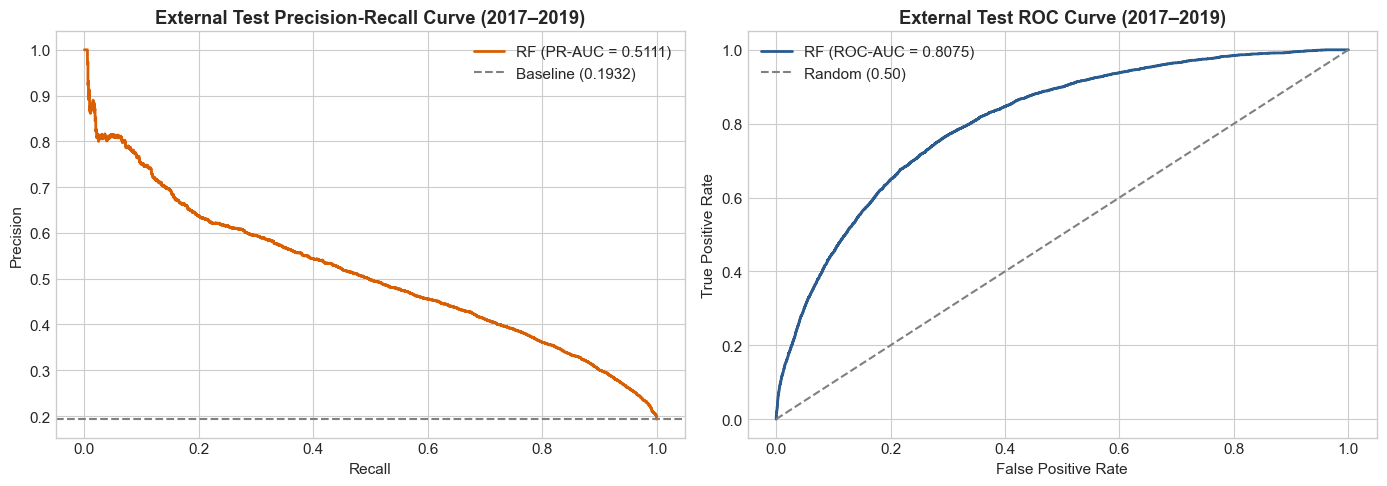

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision-Recall Curve
probs_test = final_eval['probabilities']
prec_t, rec_t, _ = precision_recall_curve(y_test, probs_test)
axes[0].plot(rec_t, prec_t, color='#d95f02', lw=2, label=f"RF (PR-AUC = {final_eval['pr_auc']:.4f})")
axes[0].axhline(y=final_eval['test_defect_prevalence'], color='gray', linestyle='--', label=f"Baseline ({final_eval['test_defect_prevalence']:.4f})")
axes[0].set_title('External Test Precision-Recall Curve (2017–2019)', fontweight='bold')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()

# ROC Curve
fpr_t, tpr_t, _ = roc_curve(y_test, probs_test)
axes[1].plot(fpr_t, tpr_t, color='#2b5c8f', lw=2, label=f"RF (ROC-AUC = {final_eval['roc_auc']:.4f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random (0.50)')
axes[1].set_title('External Test ROC Curve (2017–2019)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.tight_layout()
plt.show()


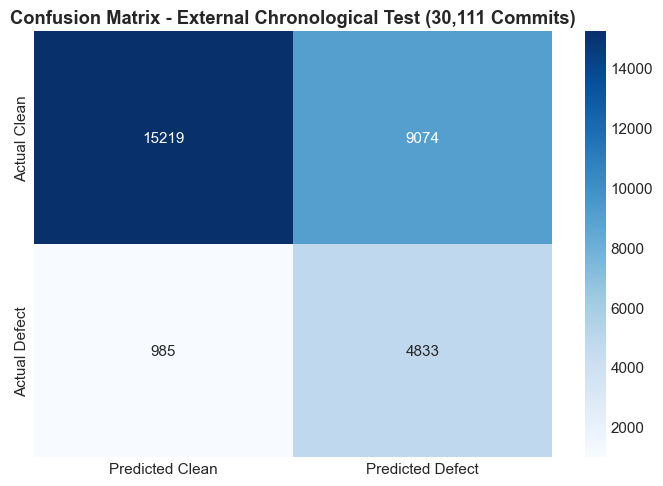

In [9]:
cm = final_eval['confusion_matrix']
cm_arr = np.array([
    [cm['true_negatives'], cm['false_positives']],
    [cm['false_negatives'], cm['true_positives']]
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_arr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted Clean', 'Predicted Defect'],
    yticklabels=['Actual Clean', 'Actual Defect']
)
plt.title('Confusion Matrix - External Chronological Test (30,111 Commits)', fontweight='bold')
plt.tight_layout()
plt.show()


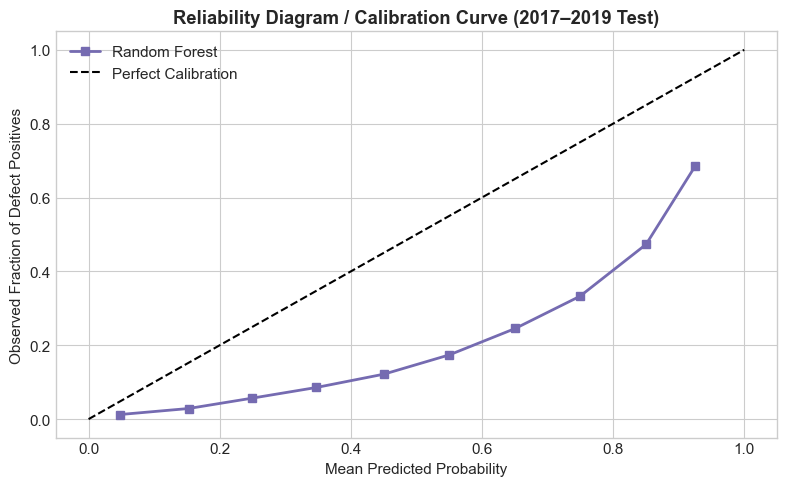

In [10]:
frac_pos, mean_pred = calibration_curve(y_test, probs_test, n_bins=10)

plt.figure(figsize=(8, 5))
plt.plot(mean_pred, frac_pos, 's-', color='#756bb1', lw=2, label='Random Forest')
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
plt.title('Reliability Diagram / Calibration Curve (2017–2019 Test)', fontweight='bold')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Fraction of Defect Positives')
plt.legend()
plt.tight_layout()
plt.show()


### Phase 3 Summary of Scientific Conclusions

1. **Chronological Model Generalization:** The Random Forest model demonstrates robust out-of-time generalizability from 2003–2016 to 2017–2019, achieving **PR-AUC = 0.5111** (a **2.65x lift** over the 0.1932 baseline prevalence) and **ROC-AUC = 0.8075**.
2. **Detection Power:** At operating threshold 0.50, the model successfully detects **83.07% of all defect-inducing commits** (4,833 of 5,818 defects) across 30,111 future commits.
3. **Class Prior Shift Awareness:** The model was trained on balanced historical data, resulting in over-confident raw probabilities relative to the 19.32% test prevalence. Scores should be utilized as **defect-risk prioritization indices** rather than absolute defect probabilities.
4. **Consistency with Phase 2 Hypotheses:** Code change size (`log1p_la`, `total_lines_changed`) and subsystem experience (`asexp`) remain the most influential features.
